# Genotype to resistance: trait determinants, effect modifiers and transfer to an unlabelled drug

**Bacterial gene presence/absence to a binary phenotype, with population structure taken into account**

A bacterial pan-genome table says, for every isolate, which accessory genes
it carries (1 = present, 0 = absent). Antimicrobial susceptibility testing
gives a binary phenotype per isolate and drug: resistant (R) or susceptible
(S). There are two common questions:

1. **Which genes drive resistance to drug *d*?** The answer should list only
   the genes that act. Linked genes, lineage markers and background loci
   should be left out.
2. **What can we say about a drug that has no phenotypes yet?** Here we have
   to borrow from related drugs that do have labels, and decide which of
   them can be trusted for the new one.

Bacterial genomes make both questions harder than they look:

- **Linkage / hitch-hiking.** Resistance genes travel on plasmids and
  transposons. Every gene on the same element looks associated with the
  phenotype. This includes *passenger* genes with no function and
  determinants for *other* drug classes.
- **Population structure.** Bacteria reproduce clonally. Each lineage has
  its own accessory-gene content and its own baseline resistance rate, so
  thousands of lineage-marker genes are associated with the phenotype
  without acting on it (Earle *et al.* 2016; Power *et al.* 2017).
- **Effect modification (epistasis).** Some genes act only on a permissive
  background, for example a low-level enzyme that gives resistance only
  when an outer-membrane porin is lost. A main-effects model then credits
  the background locus and under-scores the genes that do the work.
- **Drugs that are similar but not the same.** A combination of a
  beta-lactam with a beta-lactamase inhibitor is in the same class as the
  beta-lactam alone. Still, the inhibitor neutralises some enzymes, so a
  gene that confers resistance to the single agent may not confer it to
  the combination (Bush & Bradford 2016).

| Step | Function |
|---|---|
| Find the background locus that modifies other genes' effects | `ov.genetics.effect_modifier_scan` |
| Rank genes and choose the determinant set (conditional fit, modifier interactions, extended-BIC forward selection with genotype-PC covariates) | `ov.genetics.trait_determinants` |
| Predict an unlabelled drug from labelled class-mates, pooled or by consensus, depending on mechanistic metadata | `ov.genetics.transfer_trait_predict` |

**What this tutorial does.** We simulate a cohort of 3,000 isolates with
200 accessory genes in 8 lineages, plus phenotypes for seven drugs, so the
true answer is known. The simulation includes every difficulty listed
above. We run the three functions, check each result against the truth, and
then show the failure modes we get when parts of the method are switched
off. Gene and drug names are synthetic.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import chi2, chi2_contingency
from sklearn.metrics import matthews_corrcoef, roc_auc_score
import omicverse as ov

ov.plot_set()
T0 = time.time()
# role colours: determinant / linked (hitch-hiker or passenger) / modifier / other
COL = {'determinant': '#2a78d6', 'linked': '#eb6834', 'modifier': '#1baf7a',
       'other': '#b5b3ad'}

🔬 Starting plot initialization...
🧬 Detecting GPU devices…
🚫 No GPU devices found (CUDA/MPS/ROCm/XPU)

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: 2.3.2   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



## 1. Principle

**Conditional logistic model.** For isolate $i$ with gene vector
$x_i\in\{0,1\}^p$ and phenotype $y_i\in\{0,1\}$:

$$\operatorname{logit} P(y_i=1) = \alpha + \sum_j \beta_j x_{ij}
  + \sum_k \theta_k z_{ik},$$

where $z_{i1},\dots,z_{iK}$ are the top principal components of the genotype
matrix. These PCs stand in for lineage, as in PCA correction for human GWAS
(Price *et al.* 2006). Because all genes are in one model, a passenger that
only travels with a determinant has $\beta_j\approx 0$ once the determinant is
in the model. The PCs absorb lineage-level differences in resistance rate.

**Effect modifier.** A background locus $m$ modifies gene $j$ when

$$\operatorname{logit} P(y=1) = \alpha + \sum_j \beta_j x_j + \beta_m x_m
  + x_m\sum_{j\neq m}\gamma_j x_j .$$

`effect_modifier_scan` tries every gene as $m$. For each candidate it uses
a likelihood-ratio (LR) test to compare the model *with* interactions against
the main-effects model, $\mathrm{LR}=2(\ell_1-\ell_0)\sim\chi^2_{\mathrm{df}}$.
The top candidate is accepted if it passes Bonferroni at `modifier_alpha`.
Gene $j$ is then scored by its log-odds in the stratum where it acts,
$\max(|\beta_j|,|\beta_j+\gamma_j|)$. The modifier is scored only by its own
main effect $|\beta_m|$: it is a background, not a determinant.

**How many determinants?** The data decide this through forward selection.
Each step adds the gene with the largest likelihood gain *given the genes
already selected* (main effect plus interaction with the modifier, with
the PCs always in the model). To keep the steps fast, candidates are ranked
with Rao's score statistic (one fit per step). The exact LR is then
computed for the top three. Selection stops at the first gene that fails
the **extended BIC** (Chen & Chen 2008):

$$\mathrm{LR} > \mathrm{df}\cdot\log n + 2\gamma\log p .$$

The $2\gamma\log p$ term grows with the number of genes screened. Plain BIC
($\mathrm{df}\log n$) does not have it and is too lenient when $p$ is large.

**Transfer to an unlabelled drug.** Write the labelled class-mates as
$s=1..S$ and the target as $t$. Each source gives a model
$\hat p_s(x)$, and a pooled model $\hat p_{\mathrm{pool}}(x)$ is fitted on
all the source labels stacked together.

- **pooled**: call R if $\hat p_{\mathrm{pool}}(x)\ge 0.5$. This is the most
  efficient rule when the sources are *mechanistically equivalent* to the target.
- **consensus**: call R only if $\min_s \hat p_s(x)\ge 0.5$, so a determinant
  must act in *every* source. This is the safe rule when the target has an
  added component that no source has (for example a new inhibitor that may
  neutralise some enzymes).

Equivalence is judged only on *mechanistically relevant* metadata. These are
the number of molecules in the SMILES (`.`-separated, so a combination
product has 2) and columns that name an inhibitor, combination partner,
adjuvant or protecting agent. Other columns are recorded as incidental and
ignored.

## 2. Simulate a structured cohort with a known answer

- **8 lineages.** Each lineage has its own accessory-gene frequencies
  ($\mathrm{Beta}(0.4,0.8)$ per lineage and gene) and its own baseline
  log-odds of resistance ($\mathcal N(0,0.8^2)$). This is the population
  structure.
- **Five enzyme genes `hydA`–`hydE`.** Their carriage rate also varies by
  lineage. `hydA`, `hydB` and `hydC` act on their own. `hydD` and `hydE`
  act **only when the background locus `bg` is present** (permissive
  background, e.g. porin loss). `bg` has no effect of its own.
- **A plasmid.** `hydA` travels with `othR` (85 %), the determinant for a
  class-B drug, and with two passengers `pasA1` / `pasA2`. `hydC` has a
  passenger `pasC`.
- **Drugs.** Class A has single agents `A1`, `A2` and `A4`, and
  combinations `A3` / `A5` (agent + inhibitor X) and `A6` (agent + a new
  inhibitor Z). Both inhibitors **neutralise `hydA` and `hydB`**. `hydC`
  is inhibitor-resistant. Class B has one drug, `B1`, conferred only by `othR`.
- **Labels.** `A1`, `A2`, `A3` and `B1` are labelled, with about 10 % of
  isolates untested per drug. `A4`, `A5` and `A6` have **no labels**. Their
  true phenotypes are kept aside and used only to score the predictions.

The role genes sit at random columns with neutral IDs, so the method cannot
use column order.

In [2]:
rng = np.random.default_rng(7)
n, p, n_lin = 3000, 200, 8
lineage = rng.integers(0, n_lin, n)
freq = rng.beta(0.4, 0.8, (n_lin, p))
X = (rng.random((n, p)) < freq[lineage]).astype(float)

roles = ['hydA', 'hydB', 'hydC', 'hydD', 'hydE', 'bg', 'othR', 'pasA1', 'pasA2', 'pasC']
col_of = dict(zip(roles, rng.choice(p, len(roles), replace=False)))
gene_ids = [f'gene{j:03d}' for j in range(p)]
name = {r: gene_ids[c] for r, c in col_of.items()}          # role -> gene id
role_of = {v: k for k, v in name.items()}                   # gene id -> role
g = lambda r: X[:, col_of[r]]

carr = rng.uniform(0.05, 0.35, (5, n_lin))                  # lineage-dependent carriage
for k, r in enumerate(['hydA', 'hydB', 'hydC', 'hydD', 'hydE']):
    X[:, col_of[r]] = rng.random(n) < carr[k, lineage]
X[:, col_of['bg']] = rng.random(n) < rng.uniform(0.3, 0.8, n_lin)[lineage]
for r, src, rate, bgr in [('othR', 'hydA', 0.85, 0.05), ('pasA1', 'hydA', 0.75, 0.06),
                          ('pasA2', 'hydA', 0.65, 0.08), ('pasC', 'hydC', 0.70, 0.06)]:
    X[:, col_of[r]] = np.where(g(src) == 1, rng.random(n) < rate, rng.random(n) < bgr)

lin_eff = rng.normal(0, 0.8, n_lin)
base = -2.5 + lin_eff[lineage]
eta = {
    'single': base + 3.0*g('hydA') + 2.5*g('hydB') + 3.0*g('hydC')
              + 3.0*g('hydD')*g('bg') + 2.5*g('hydE')*g('bg'),
    'combo':  base + 3.0*g('hydC') + 3.0*g('hydD')*g('bg') + 2.5*g('hydE')*g('bg'),
    'other':  base + 3.5*g('othR'),
}
draw = lambda e: (rng.random(n) < 1/(1 + np.exp(-e))).astype(float)
mech = {'A1': 'single', 'A2': 'single', 'A3': 'combo', 'A4': 'single',
        'A5': 'combo', 'A6': 'combo', 'B1': 'other'}
isolates = [f'iso{i:04d}' for i in range(n)]
genomes = pd.DataFrame(X, columns=gene_ids, index=isolates)
Y_true = pd.DataFrame({d: draw(eta[m]) for d, m in mech.items()}, index=isolates)

labels = Y_true[['A1', 'A2', 'A3', 'B1']].copy()            # A4/A5/A6: no labels at all
for c in labels:
    labels.loc[rng.random(n) < 0.10, c] = np.nan

truth = {'A1': {name[r] for r in ['hydA', 'hydB', 'hydC', 'hydD', 'hydE']},
         'A3': {name[r] for r in ['hydC', 'hydD', 'hydE']},
         'B1': {name['othR']}}
print('genomes', genomes.shape, '| labelled drugs', list(labels.columns))
print('resistance rate (labelled):', labels.mean().round(2).to_dict())
pd.Series(name, name='gene id').to_frame().T

genomes (3000, 200) | labelled drugs ['A1', 'A2', 'A3', 'B1']
resistance rate (labelled): {'A1': 0.43, 'A2': 0.43, 'A3': 0.28, 'B1': 0.22}


            hydA     hydB     hydC     hydD     hydE       bg     othR  \
gene id  gene028  gene164  gene079  gene138  gene140  gene170  gene133   

           pasA1    pasA2     pasC  
gene id  gene056  gene128  gene154  

The lineage baselines produce strong lineage-level differences in
resistance, even among isolates that carry no `hyd` gene:

In [3]:
none_carried = (X[:, [col_of[r] for r in ['hydA', 'hydB', 'hydC', 'hydD', 'hydE']]].sum(1) == 0)
tab = (pd.DataFrame({'lineage': lineage, 'R': Y_true['A1'].to_numpy(), 'none': none_carried})
       .query('none').groupby('lineage')['R'].agg(['mean', 'size']).round(3))
tab.columns = ['A1 resistance rate (no hyd gene)', 'n isolates']
tab.T

lineage                                 0       1        2        3       4  \
A1 resistance rate (no hyd gene)    0.008   0.013    0.123    0.027   0.056   
n isolates                        126.000  79.000  114.000  147.000  71.000   

lineage                                 5       6        7  
A1 resistance rate (no hyd gene)    0.046   0.051    0.223  
n isolates                        151.000  98.000  157.000  

## 3. The naive approach: one gene at a time

A marginal $\chi^2$ test per gene against `A1` is the first thing most
people try. The colour of each bar shows the true role of the gene.

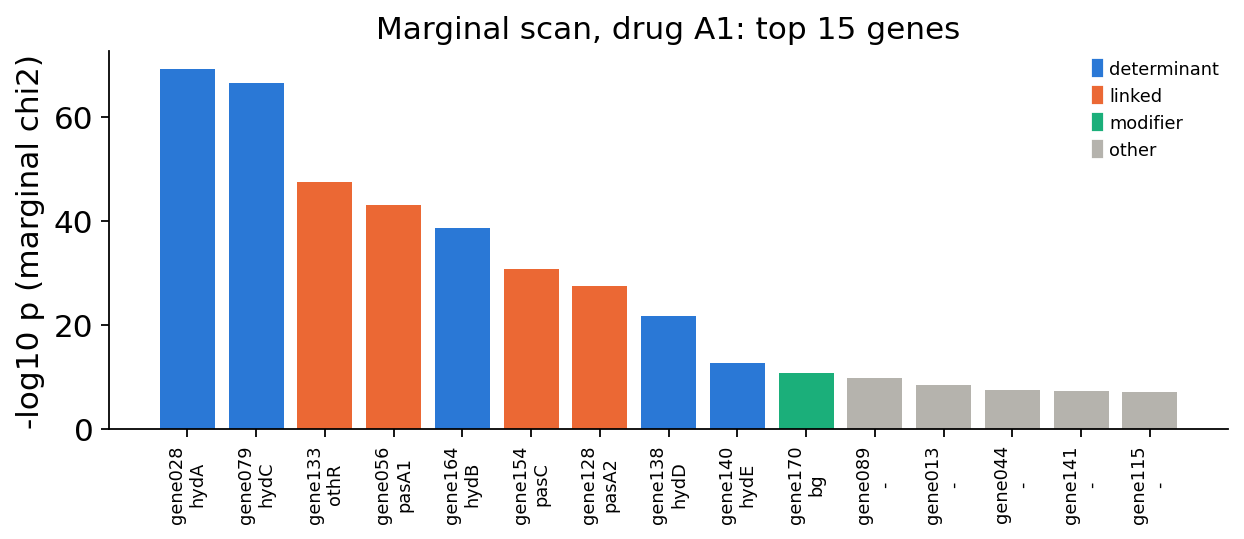

    feature   role       p_value        class
0   gene028   hydA  7.883060e-70  determinant
1   gene079   hydC  3.366713e-67  determinant
2   gene133   othR  3.182310e-48       linked
3   gene056  pasA1  8.209181e-44       linked
4   gene164   hydB  2.724397e-39  determinant
5   gene154   pasC  1.697851e-31       linked
6   gene128  pasA2  2.894374e-28       linked
7   gene138   hydD  2.151811e-22  determinant
8   gene140   hydE  2.747604e-13  determinant
9   gene170     bg  2.176084e-11     modifier
10  gene089      -  1.667255e-10        other
11  gene013      -  3.851086e-09        other
12  gene044      -  3.578320e-08        other
13  gene141      -  6.361801e-08        other
14  gene115      -  8.111894e-08        other

In [4]:
def marginal_scan(G, y):
    ok = y.notna()
    out = []
    for c in G.columns:
        t = pd.crosstab(G.loc[ok, c], y[ok]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
        out.append((c, chi2_contingency(t)[1]))
    return pd.DataFrame(out, columns=['feature', 'p_value']).sort_values('p_value').reset_index(drop=True)

def role_class(f, drug):
    if f in truth.get(drug, ()):
        return 'determinant'
    if f == name['bg']:
        return 'modifier'
    if role_of.get(f) in ('othR', 'pasA1', 'pasA2', 'pasC') or f in set().union(*truth.values()):
        return 'linked'
    return 'other'

marg = marginal_scan(genomes, labels['A1'])
marg['role'] = [role_of.get(f, '-') for f in marg.feature]
marg['class'] = [role_class(f, 'A1') for f in marg.feature]
top = marg.head(15)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(range(len(top)), -np.log10(top.p_value.clip(lower=1e-300)),
       color=[COL[c] for c in top['class']], width=0.8)
ax.set_xticks(range(len(top)))
ax.set_xticklabels([f"{f}\n{r}" for f, r in zip(top.feature, top.role)], rotation=90, fontsize=8)
ax.set_ylabel('-log10 p (marginal chi2)')
ax.set_title('Marginal scan, drug A1: top 15 genes')
ax.legend(handles=[Patch(color=COL[k], label=k) for k in ['determinant', 'linked', 'modifier', 'other']],
          frameon=False, fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()
top[['feature', 'role', 'p_value', 'class']]

**Reading the marginal scan.** The determinants are near the top. Mixed in
with them are the plasmid partners of `hydA` (`othR`, `pasA1`, `pasA2`), the
passenger of `hydC`, the background locus `bg`, and below them a run of
lineage markers ("other") with tiny p-values. A top-*k* list from this scan
would mix all five kinds of gene. The conditional analysis below separates
them.

## 4. Screening for an effect modifier

`effect_modifier_scan` fits a main-effects model and keeps the
`shortlist` genes with the largest |coefficient|. Then, for every gene $m$
present in 5–95 % of isolates, it tests whether adding the interactions
$x_m\cdot x_j$ improves the fit.

In [5]:
t = time.time()
scan = ov.genetics.effect_modifier_scan(genomes, labels['A1'])
print(f'{len(scan)} candidates screened in {time.time()-t:.1f} s')
scan['role'] = [role_of.get(f, '-') for f in scan.modifier]
scan.head(6)

200 candidates screened in 5.4 s


  modifier       loglik     lr_stat  df       p_value  frac_present  \
0  gene170 -1082.393380  206.169122  29  1.275965e-28      0.525109   
1  gene138 -1110.941285  149.073312  29  4.245559e-18      0.212154   
2  gene140 -1141.801824   87.352235  29  9.252154e-08      0.184862   
3  gene186 -1151.687374   66.316462  30  1.484624e-04      0.401747   
4  gene034 -1149.715032   61.624239  30  5.828069e-04      0.340247   
5  gene183 -1153.708098   60.450601  30  8.117066e-04      0.319505   

   lr_ratio_to_next  role  
0          1.383005    bg  
1          1.706577  hydD  
2          1.317203  hydE  
3          1.076142     -  
4          1.019415     -  
5          1.025343     -  

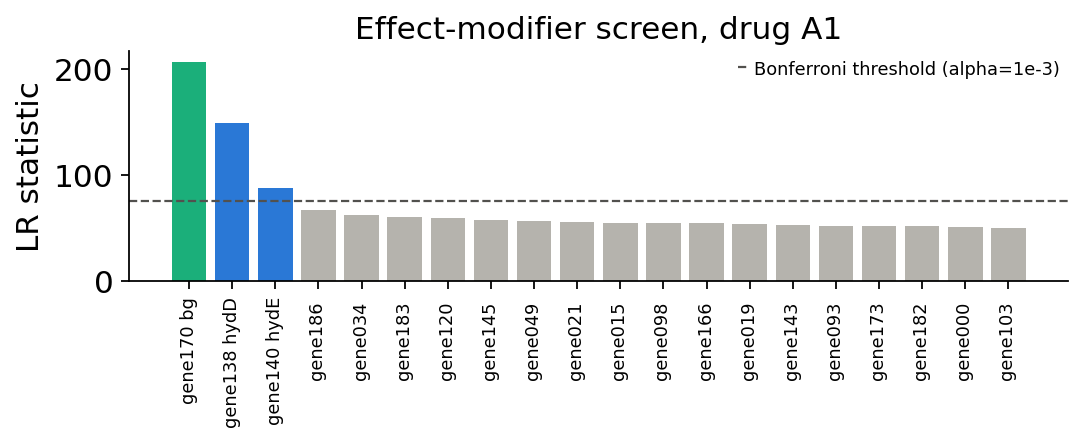

In [6]:
fig, ax = plt.subplots(figsize=(7, 3))
s = scan.head(20)
ax.bar(range(len(s)), s.lr_stat, width=0.8,
       color=[COL[role_class(f, 'A1')] if f in role_of else COL['other'] for f in s.modifier])
ax.axhline(chi2.isf(1e-3/len(scan), scan.loc[0, 'df']),
           color='#52514e', lw=1, ls='--', label='Bonferroni threshold (alpha=1e-3)')
ax.set_xticks(range(len(s)))
ax.set_xticklabels([f"{f} {role_of.get(f, '')}" for f in s.modifier], rotation=90, fontsize=8)
ax.set_ylabel('LR statistic'); ax.set_title('Effect-modifier screen, drug A1')
ax.legend(frameon=False, fontsize=8); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

**Reading the screen.** The top candidate is the simulated background
locus `bg`. The next two rows are `hydD` and `hydE`. They are also above the
Bonferroni line, and this is expected: an interaction is symmetric, so the
term $x_{\mathrm{bg}}x_{\mathrm{hydD}}$ is also available when `hydD` is tried
as the "modifier". As a modifier, though, `hydD` explains only its own
pair. `bg` explains both the `hydD` and the `hydE` interaction, so it has
the largest LR. Only the top row is used (Bonferroni over all candidates).
After it come the ordinary genes, with LRs close to each other
(`lr_ratio_to_next` ≈ 1).

*Caveat.* If a background acted on only **one** determinant, the
determinant and the background would be interchangeable in this screen. The
modifier would then be chosen by a small likelihood margin. In that case,
report both rows and decide on biological grounds.

## 5. Ranking determinants and choosing the set

`trait_determinants` runs the screen internally (`modifier='auto'`). It
then refits with modifier interactions, scores every gene, and runs the
extended-BIC forward selection with 10 genotype PCs as covariates
(`select='ebic'`, `n_pcs=10`, the defaults).

In [7]:
t = time.time()
res_A1 = ov.genetics.trait_determinants(genomes, labels['A1'])
print(f'{time.time()-t:.1f} s | modifier = {res_A1.attrs["modifier"]} ({role_of.get(res_A1.attrs["modifier"])})'
      f' | n_determinants = {res_A1.attrs["n_determinants"]}')
show = res_A1.head(8).copy()
show.insert(1, 'role', [role_of.get(f, '-') for f in show.feature])
show[['feature', 'role', 'score', 'is_determinant', 'beta_main', 'beta_with_modifier', 'acts_in',
      'selection_step', 'selection_lr']].round(2)

6.1 s | modifier = gene170 (bg) | n_determinants = 5


   feature  role  score  is_determinant  beta_main  beta_with_modifier  \
0  gene079  hydC   3.63            True       3.49                3.63   
1  gene138  hydD   3.38            True       0.38                3.38   
2  gene164  hydB   2.87            True       2.71                2.87   
3  gene028  hydA   2.66            True       2.51                2.66   
4  gene140  hydE   2.26            True       0.17                2.26   
5  gene101     -   0.92           False       0.08                0.92   
6  gene129     -   0.90           False       0.17                0.90   
7  gene002     -   0.76           False      -0.20                0.76   

            acts_in  selection_step  selection_lr  
0               all             3.0        131.18  
1  modifier_present             1.0        204.98  
2               all             2.0        224.80  
3               all             5.0         45.90  
4  modifier_present             4.0        124.73  
5  modifier_present  

In [8]:
path = res_A1.attrs['selection_path']
path.assign(role=[role_of.get(f, '-') for f in path.feature]).round(3)

   feature  lr_stat  df  p_value  n_candidates_left  accepted  role
0  gene138  204.980   2    0.000                 40      True  hydD
1  gene164  224.804   2    0.000                 39      True  hydB
2  gene079  131.177   2    0.000                 38      True  hydC
3  gene140  124.729   2    0.000                 37      True  hydE
4  gene028   45.903   2    0.000                 36      True  hydA
5  gene035   11.240   2    0.004                 35     False     -

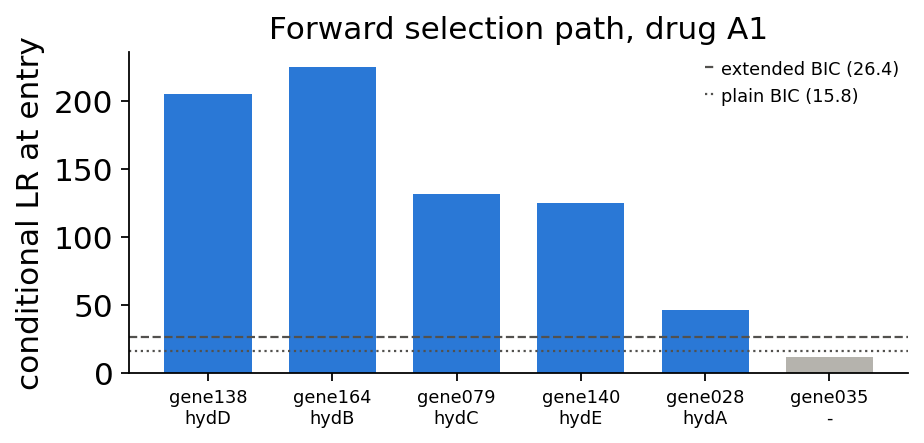

In [9]:
n_lab, p_all = int(labels['A1'].notna().sum()), genomes.shape[1]
ebic_thr = 2*np.log(n_lab) + 2*np.log(p_all)          # df = 2 (main + interaction) with a modifier
bic_thr = 2*np.log(n_lab)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(range(len(path)), path.lr_stat, width=0.7,
       color=[COL['determinant'] if a else COL['other'] for a in path.accepted])
ax.axhline(ebic_thr, color='#52514e', lw=1, ls='--', label=f'extended BIC ({ebic_thr:.1f})')
ax.axhline(bic_thr, color='#52514e', lw=1, ls=':', label=f'plain BIC ({bic_thr:.1f})')
ax.set_xticks(range(len(path)))
ax.set_xticklabels([f"{f}\n{role_of.get(f, '-')}" for f in path.feature], fontsize=8)
ax.set_ylabel('conditional LR at entry'); ax.set_title('Forward selection path, drug A1')
ax.legend(frameon=False, fontsize=8); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

**Reading the result.**

- The modifier found is `bg`. The five selected genes are exactly `hydA`–`hydE`.
  `hydD` and `hydE` have `acts_in = 'modifier_present'`: with `bg` absent
  their `beta_main` is small, and with `bg` present (`beta_with_modifier`)
  it is large.
- `bg` is flagged `is_modifier` and is *not* a determinant, because its own
  main effect fails the drop-one extended-BIC test.
- The plasmid partners of `hydA` (`othR`, `pasA1`, `pasA2`) are not
  selected: once `hydA` is in the model they add nothing. Neither are the
  lineage markers, because the PCs absorb the lineage baselines.
- The selection path shows why five is the right size. True determinants
  enter with LR far above the threshold, and the first rejected candidate
  falls below it. It is the size of this gap, rather than a fixed top-*k*,
  that sets the number of determinants.

The same call on the inhibitor combination `A3` and on the class-B drug
`B1` returns those drugs' own determinant sets:

In [10]:
rows = []
for d in ['A1', 'A3', 'B1']:
    r = res_A1 if d == 'A1' else ov.genetics.trait_determinants(genomes, labels[d])
    sel = list(r.loc[r.is_determinant, 'feature'])
    rows.append({'drug': d, 'modifier': role_of.get(r.attrs['modifier'], r.attrs['modifier']),
                 'selected': ', '.join(role_of.get(f, f) for f in sel),
                 'exact match to truth': set(sel) == truth[d]})
pd.DataFrame(rows)

  drug modifier                      selected  exact match to truth
0   A1       bg  hydC, hydD, hydB, hydA, hydE                  True
1   A3       bg              hydD, hydC, hydE                  True
2   B1     None                          othR                  True

For `A3`, `hydA` and `hydB` drop out: the inhibitor neutralises them. `othR`
is the only determinant of `B1`, so the gene that was a hitch-hiker for `A1`
is a genuine determinant for another class. `B1` has no modifier
(`None`) because no gene modifies `othR`.

## 6. Transfer to drugs without labels

Drug metadata is usually a table: class, a SMILES string, sometimes the
combination partner, and assorted incidental columns. **Pass the whole
table** as `groups`. The SMILES below are toy strings, and only their
`.`-separated component count is used.

In [11]:
drug_meta = pd.DataFrame({
    'drug_class': ['A', 'A', 'A', 'A', 'A', 'A', 'B'],
    'generation': ['1', '2', '3', '2', '3', '4', '1'],          # incidental
    'smiles': ['O=C1CCN1C(=O)C', 'O=C1CCN1CC(=O)O', 'O=C1CCN1C(=O)C.O=C(O)C1CS(=O)(=O)C1',
               'O=C1CCN1CCC(=O)O', 'O=C1CCN1CC(=O)O.O=C(O)C1CS(=O)(=O)C1',
               'O=C1CCN1C(=O)C.OB1OCCC1', 'CC1=CC(=O)OC1'],
    'inhibitor': ['none', 'none', 'inhX', 'none', 'inhX', 'inhZ', 'none'],
}, index=['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'B1'])
drug_meta.assign(labelled=drug_meta.index.isin(labels.columns))     # display only

   drug_class generation                                smiles inhibitor  \
A1          A          1                        O=C1CCN1C(=O)C      none   
A2          A          2                       O=C1CCN1CC(=O)O      none   
A3          A          3   O=C1CCN1C(=O)C.O=C(O)C1CS(=O)(=O)C1      inhX   
A4          A          2                      O=C1CCN1CCC(=O)O      none   
A5          A          3  O=C1CCN1CC(=O)O.O=C(O)C1CS(=O)(=O)C1      inhX   
A6          A          4               O=C1CCN1C(=O)C.OB1OCCC1      inhZ   
B1          B          1                         CC1=CC(=O)OC1      none   

    labelled  
A1      True  
A2      True  
A3      True  
A4     False  
A5     False  
A6     False  
B1      True  

In [12]:
def evaluate(r, target):
    yt = Y_true[target]
    return {'target': target, 'requested': r['decision_requested'], 'decision': r['decision'],
            'sources': ','.join(r['sources']),
            'MCC': round(matthews_corrcoef(yt, r['call']), 3),
            'AUROC': round(roc_auc_score(yt, r['proba']), 3),
            'n_warnings': len(r['warnings'])}

results = {}
for tgt in ['A4', 'A5', 'A6']:
    results[tgt] = ov.genetics.transfer_trait_predict(genomes, labels, tgt,
                                                      groups=drug_meta)
pd.DataFrame([evaluate(results[t], t) for t in results])

  target requested   decision   sources    MCC  AUROC  n_warnings
0     A4      auto     pooled     A1,A2  0.535  0.860           0
1     A5      auto     pooled        A3  0.461  0.840           0
2     A6      auto  consensus  A1,A2,A3  0.423  0.818           0

With `decision='auto'` (the default) each target gets a different rule, and
`decision_reasons` explains the choice:

In [13]:
for tgt in ['A4', 'A6']:
    print(f'--- {tgt}')
    for line in results[tgt]['decision_reasons']:
        print('  *', line)
results['A6']['source_match']

--- A4
  * sources share the target's drug_class and its relevant attributes ['inhibitor', 'n_components'] -> treated as mechanistically equivalent
  * columns not treated as mechanistic (incidental): ['generation']
  * decision 'pooled'
  * label-free agreement: largest gap between source models on carriers of one determinant = 0.07 (gene079); overall source_call_disagreement = 0.275
--- A6
  * the target differs from every labelled drug_class-mate on relevant attributes {'inhibitor': 'inhZ', 'n_components': 2} (e.g. an added component) -> determinants must act in all sources to be trusted
  * columns not treated as mechanistic (incidental): ['generation']
  * decision 'consensus'
  * label-free agreement: largest gap between source models on carriers of one determinant = 0.63 (gene028); overall source_call_disagreement = 0.682


  source inhibitor  n_components  relevant_match  used
0     A1      none             1           False  True
1     A2      none             1           False  True
2     A3      inhX             2           False  True

- **`A4`** (single agent): `A1` and `A2` match it on `n_components = 1` and
  `inhibitor = none`. The different `generation` value is recorded as
  incidental. Decision: **pooled** over `A1`+`A2`. The combination `A3` is
  not used.
- **`A5`** (agent + inhibitor X): `A3` has the same partner, so the rule is
  **pooled** over `A3` alone.
- **`A6`** (agent + new inhibitor Z): no labelled class-mate has inhibitor Z,
  so the rule is **consensus** over *all* class-A sources. An isolate is
  called R only if the `A1`, `A2` **and** `A3` models all call it R.

For `A6` we can check label-free whether the sources agree. The table below
shows, for the carriers of each strongly weighted gene, the fraction that
each source model calls R:

In [14]:
r6 = results['A6']
agree = r6['determinant_agreement'].head(6).copy()
agree.insert(1, 'role', [role_of.get(f, '-') for f in agree.feature])
display(agree.round(2))
disc = r6['discordant_features'].head(6).copy()
disc.insert(0, 'role', [role_of.get(f, '-') for f in disc.index])
disc.round(2)

   feature   role  n_carriers  called_A1  called_A2  called_A3  max_rate_gap
0  gene028   hydA         693       0.79       0.83       0.20          0.63
1  gene056  pasA1         666       0.72       0.76       0.21          0.56
2  gene164   hydB         541       0.72       0.77       0.25          0.52
3  gene172      -         359       0.48       0.52       0.26          0.26
4  gene033      -        1097       0.46       0.47       0.22          0.25
5  gene194      -         759       0.46       0.48       0.24          0.24

         role    A1    A2    A3  spread
gene164  hydB  2.16  2.42  0.07    2.35
gene028  hydA  2.32  2.57  0.51    2.06
gene101     -  0.28  0.62 -0.24    0.86
gene114     - -0.19  0.26 -0.43    0.69
gene008     - -0.01  0.03  0.67    0.68
gene157     -  0.06 -0.58 -0.11    0.64

In [15]:
print('leave-one-source-out validation inside the A6 sources:')
r6['validation'].round(3)

leave-one-source-out validation inside the A6 sources:


  held_out trained_on     n  auroc    mcc
0       A1      A2,A3  2748  0.848  0.493
1       A2      A1,A3  2713  0.827  0.468
2       A3      A1,A2  2716  0.752  0.334

**Reading the transfer output.**

- `determinant_agreement`: carriers of `hydA` (and of `hydB` and the
  plasmid genes linked to `hydA`) are called R by the `A1`/`A2` models but
  mostly S by the `A3` model. The sources disagree about `hydA`, which is
  the inhibitor neutralisation built into the simulation. This check needs
  no target labels.
- `discordant_features` shows the same thing at the coefficient level:
  the largest spread across the per-source coefficients is at `hydA` and `hydB`.
- `validation` (leave one source out) shows that when the held-out source
  is `A3` the remaining single-agent models transfer poorly. This is
  further evidence that the class is not homogeneous.

Scored against the hidden truth, all three targets get a useful prediction.
The **`A6`** consensus calls do not trust `hydA`/`hydB`. The next section
shows what happens when they are trusted.

In [16]:
carriers = (genomes[name['hydA']].eq(1) | genomes[name['hydB']].eq(1)) & \
           genomes[[name['hydC']]].eq(0).all(axis=1) & \
           ~(genomes[[name['hydD'], name['hydE']]].eq(1).any(axis=1) & genomes[name['bg']].eq(1))
print(f'{carriers.sum()} isolates carry hydA/hydB but no determinant that acts under an inhibitor;')
print(f'true A6 resistance rate among them: {Y_true.loc[carriers, "A6"].mean():.2f}; '
      f'called R by consensus: {r6["call"][carriers].mean():.2f}')

719 isolates carry hydA/hydB but no determinant that acts under an inhibitor;
true A6 resistance rate among them: 0.11; called R by consensus: 0.02


## 7. Pitfalls (executed)

### 7a. Plain BIC without the lineage covariates admits lineage markers

In [17]:
loose = ov.genetics.trait_determinants(genomes, labels['A1'], select='bic', n_pcs=0)
sel = list(loose.loc[loose.is_determinant, 'feature'])
extra = [f for f in sel if f not in truth['A1']]
lin_mean = pd.DataFrame(X, columns=gene_ids).groupby(lineage).mean()     # carriage per lineage
print('selected:', len(sel), '| true determinants found:', len(set(sel) & truth['A1']),
      '| extra genes:', extra)
pd.DataFrame({'gene': extra,
              'role': [role_of.get(f, 'none (not causal)') for f in extra],
              'corr(lineage carriage, lineage baseline)':
                  [round(np.corrcoef(lin_mean[f], lin_eff)[0, 1], 2) for f in extra],
              'selection_lr': loose.set_index('feature').loc[extra, 'selection_lr'].round(1).to_numpy()})

selected: 9 | true determinants found: 5 | extra genes: ['gene115', 'gene099', 'gene156', 'gene090']


      gene               role  corr(lineage carriage, lineage baseline)  \
0  gene115  none (not causal)                                     -0.51   
1  gene099  none (not causal)                                      0.61   
2  gene156  none (not causal)                                     -0.44   
3  gene090  none (not causal)                                     -0.53   

   selection_lr  
0          25.8  
1          47.9  
2          23.0  
3          30.0  

The extra genes are non-causal. Their carriage across the 8 lineages is
correlated with the lineages' baseline resistance ($|r|\approx 0.4$–$0.6$).
They are lineage markers that stand in for the lineage effect, which
nothing else in the model explains. Their LRs (about 23–48) clear plain
BIC ($\mathrm{df}\log n\approx 16$). Which part of the default protects
against them, the penalty or the PCs? The ablation below answers this:

In [18]:
abl = []
for sel_, npc in [('bic', 0), ('ebic', 0), ('bic', 10), ('ebic', 10)]:
    r = loose if (sel_, npc) == ('bic', 0) else \
        ov.genetics.trait_determinants(genomes, labels['A1'], select=sel_, n_pcs=npc)
    s_ = set(r.loc[r.is_determinant, 'feature'])
    abl.append({'select': sel_, 'n_pcs': npc, 'n_selected': len(s_),
                'true found': len(s_ & truth['A1']), 'extra (non-causal)': len(s_ - truth['A1'])})
pd.DataFrame(abl)

  select  n_pcs  n_selected  true found  extra (non-causal)
0    bic      0           9           5                   4
1   ebic      0           7           5                   2
2    bic     10           5           5                   0
3   ebic     10           5           5                   0

Without PCs, the extended-BIC penalty alone still lets in two of the four
lineage markers. With PCs, plain BIC is enough in this cohort of 200 genes. The
$\log p$ term matters more when tens of thousands of genes or unitigs are
screened. The defaults (`select='ebic'`, `n_pcs=10`) combine both
safeguards and give the exact set (section 5).

### 7b. Ignoring the effect modifier

In [19]:
nomod = ov.genetics.trait_determinants(genomes, labels['A1'], modifier=None)
a, b = res_A1.set_index('feature'), nomod.set_index('feature')
genes_cmp = [name[r] for r in ['hydA', 'hydB', 'hydC', 'hydD', 'hydE', 'bg']]
pd.DataFrame({'role': [role_of[f] for f in genes_cmp],
              'true log-odds (where it acts)': [3.0, 2.5, 3.0, 3.0, 2.5, 0.0],
              'score, modifier=auto': a.loc[genes_cmp, 'score'].round(2).to_numpy(),
              'acts_in, auto': a.loc[genes_cmp, 'acts_in'].to_numpy(),
              'rank, auto': a.loc[genes_cmp, 'rank'].to_numpy(),
              'score, modifier=None': b.loc[genes_cmp, 'score'].round(2).to_numpy(),
              'rank, None': b.loc[genes_cmp, 'rank'].to_numpy(),
              'determinant, None': b.loc[genes_cmp, 'is_determinant'].to_numpy()},
             index=genes_cmp)

         role  true log-odds (where it acts)  score, modifier=auto  \
gene028  hydA                            3.0                  2.66   
gene164  hydB                            2.5                  2.87   
gene079  hydC                            3.0                  3.63   
gene138  hydD                            3.0                  3.38   
gene140  hydE                            2.5                  2.26   
gene170    bg                            0.0                  0.33   

            acts_in, auto  rank, auto  score, modifier=None  rank, None  \
gene028               all           4                  2.32           2   
gene164               all           3                  2.16           3   
gene079               all           1                  2.93           1   
gene138  modifier_present           2                  1.65           4   
gene140  modifier_present           5                  1.10           5   
gene170       is_modifier          69                  0.97

With main effects only, the selection still finds the five genes in this
cohort. The *effect sizes* are wrong, though. `hydD` and `hydE` get one
log-odds averaged over isolates with and without `bg` (about half of the
true 3.0 / 2.5). They drop to the bottom of the ranking and lose the
information that they act only with `bg` (`acts_in`). In a cohort where
fewer isolates carry the background, or where the modified effects are
weaker, the averaged effect can fall below the selection threshold.
Meanwhile `bg` absorbs part of the signal. Its main effect triples (score
0.33 → 0.97) and it moves from rank 69 to rank 6, just below the selection
threshold here. In a less favourable cohort it would be admitted as a
"determinant". Keep the default `modifier='auto'`. If the screen finds no
modifier (as for `B1`), the result is the same as with `modifier=None`.

### 7c. Forcing `decision='pooled'` when the target has an added component

In [20]:
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter('always')
    r_req = ov.genetics.transfer_trait_predict(genomes, labels, 'A6', groups=drug_meta,
                                               decision='pooled')
    r_forced = ov.genetics.transfer_trait_predict(genomes, labels, 'A6', groups=drug_meta,
                                                  decision='pooled', force=True)
print('requested pooled  ->', r_req['decision'], '|', r_req['warnings'][0][:110], '...')
print('forced pooled     ->', r_forced['decision'], '| warnings:', len(r_forced['warnings']))
for m in r_forced['warnings']:
    print('   *', m[:140])
print(f'source_call_disagreement = {r_forced["source_call_disagreement"]:.2f}')

requested pooled  -> consensus | decision='pooled' was requested but the metadata shows the target differs from every source (see source_match) ...
forced pooled     -> pooled | warnings: 2
   * decision='pooled' was FORCED although the metadata shows the target differs from every source (see source_match); determinants that act in s
   * the per-source models disagree on 68.2% of the samples any source calls positive (inconsistent determinant effects, see discordant_features)
source_call_disagreement = 0.68


### 7d. Passing only a class column as metadata

In [21]:
with warnings.catch_warnings(record=True):
    warnings.simplefilter('always')
    r_cls = ov.genetics.transfer_trait_predict(genomes, labels, 'A6',
                                               groups=dict(zip(drug_meta.index, drug_meta.drug_class)))
print(r_cls['decision'], r_cls['sources'])
print('warning:', r_cls['warnings'][0][:160], '...')

pooled ['A1', 'A2', 'A3']


                                 setting   decision   sources    MCC  AUROC  \
0  whole metadata, decision unset (auto)  consensus  A1,A2,A3  0.423  0.818   
1         decision='pooled' (overridden)  consensus  A1,A2,A3  0.423  0.818   
2          decision='pooled', force=True     pooled  A1,A2,A3  0.383  0.791   
3                      class column only     pooled  A1,A2,A3  0.383  0.791   

   R-call rate, hydA/B-only carriers  n_warnings  
0                               0.02           0  
1                               0.02           1  
2                               0.34           2  
3                               0.34           2  

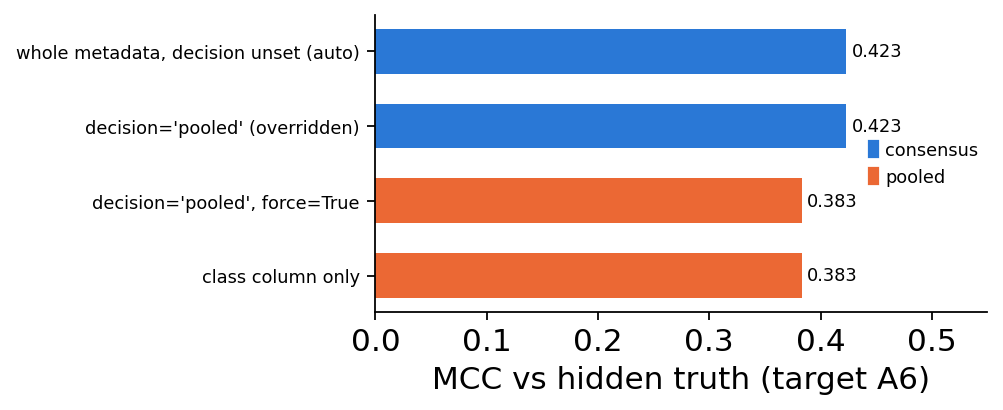

In [22]:
cmp = pd.DataFrame([
    {**evaluate(results['A6'], 'A6'), 'setting': 'whole metadata, decision unset (auto)'},
    {**evaluate(r_req, 'A6'), 'setting': "decision='pooled' (overridden)"},
    {**evaluate(r_forced, 'A6'), 'setting': "decision='pooled', force=True"},
    {**evaluate(r_cls, 'A6'), 'setting': 'class column only'},
])
cmp['R-call rate, hydA/B-only carriers'] = [round(r['call'][carriers].mean(), 2)
                                            for r in (results['A6'], r_req, r_forced, r_cls)]
cmp = cmp[['setting', 'decision', 'sources', 'MCC', 'AUROC', 'R-call rate, hydA/B-only carriers', 'n_warnings']]
display(cmp)

fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.barh(range(len(cmp))[::-1], cmp.MCC, height=0.6,
        color=[COL['determinant'] if d == 'consensus' else COL['linked'] for d in cmp.decision])
ax.set_yticks(range(len(cmp))[::-1]); ax.set_yticklabels(cmp.setting, fontsize=8)
for k, v in enumerate(cmp.MCC):
    ax.text(v + 0.005, len(cmp) - 1 - k, f'{v:.3f}', va='center', fontsize=8)
ax.set_xlabel('MCC vs hidden truth (target A6)')
ax.set_xlim(0, cmp.MCC.max() * 1.3)
ax.legend(handles=[Patch(color=COL['determinant'], label='consensus'), Patch(color=COL['linked'], label='pooled')],
          frameon=False, fontsize=8, loc='center right'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

**Reading the pitfalls.**

- A *requested* `'pooled'` that contradicts the metadata is switched to
  `'consensus'` with a `UserWarning`. Only `force=True` keeps it. The forced
  pooled model calls about a third of the `hydA`/`hydB`-only carriers
  resistant, although under inhibitor Z only about one in ten is, and
  MCC drops. `source_call_disagreement` and the second warning flag the
  problem without any target labels.
- Passing **only the class** removes the evidence. The function cannot see
  that `A6` has an added component, warns that equivalence cannot be
  checked, pools all class-mates, and makes the same mistake as the forced
  pooled run. Pass the whole metadata table, leave `decision` unset, and
  print `r['warnings']`.
- The opposite mistake also costs accuracy. Consensus is not a free safety
  margin. When the sources really are equivalent (`A4`), pooling uses all
  labels, and taking the per-source minimum only loses sensitivity (next
  cell). That is why `'auto'` pools whenever the relevant metadata match.
- `source_call_disagreement` is not zero even for equivalent sources
  (about 0.27 for `A1` vs `A2` when predicting `A4`, against 0.68 for `A6`), because isolates near the 0.5
  threshold flip between two models fitted on noisy labels. Treat it as a
  comparison between targets, not as an absolute test.

In [23]:
r4c = ov.genetics.transfer_trait_predict(genomes, labels, 'A4', groups=drug_meta, decision='consensus')
pd.DataFrame([evaluate(results['A4'], 'A4'), evaluate(r4c, 'A4')])

  target  requested   decision sources    MCC  AUROC  n_warnings
0     A4       auto     pooled   A1,A2  0.535  0.860           0
1     A4  consensus  consensus   A1,A2  0.512  0.855           0

In [24]:
print(f'total runtime {time.time()-T0:.0f} s')

total runtime 50 s


## 8. Summary

| Question | Call | Key outputs |
|---|---|---|
| Is there a background locus? | `effect_modifier_scan(X, y)` | `lr_stat`, `p_value`, `lr_ratio_to_next` |
| Which genes drive the trait, and how many? | `trait_determinants(X, y)` | `is_determinant`, `acts_in`, `attrs['modifier']`, `attrs['selection_path']` |
| What about a drug without labels? | `transfer_trait_predict(X, Y, target, groups=<whole metadata table>)` | `decision`, `decision_reasons`, `source_match`, `determinant_agreement`, `discordant_features`, `validation`, `warnings` |

Practical notes:

- Use `direction='risk'` when only resistance-*conferring* genes are wanted.
  A selected gene whose conditional effect is protective is then not flagged.
- The PCs are computed from the genotype matrix. With very few lineages
  or very small cohorts, lower `n_pcs`. When thousands of genes are
  screened, keep `select='ebic'`.
- The modifier screen tests one background locus. Several independent
  modifiers, or higher-order epistasis, need a dedicated model.
- Transfer can only be as good as the metadata. If nothing in the table
  separates the target from its sources, `'auto'` pools. In that case,
  inspect `determinant_agreement` / `discordant_features` and choose
  `decision='consensus'` explicitly if a determinant is split across sources.

## 9. References

- Chen J., Chen Z. (2008). Extended Bayesian information criteria for model
  selection with large model spaces. *Biometrika* 95(3):759–771.
  [doi:10.1093/biomet/asn034](https://doi.org/10.1093/biomet/asn034)
- Price A. L. *et al.* (2006). Principal components analysis corrects for
  stratification in genome-wide association studies. *Nature Genetics*
  38(8):904–909. [doi:10.1038/ng1847](https://doi.org/10.1038/ng1847)
- Rao C. R. (1948). Large sample tests of statistical hypotheses concerning
  several parameters with applications to problems of estimation.
  *Mathematical Proceedings of the Cambridge Philosophical Society*
  44(1):50–57. [doi:10.1017/S0305004100023987](https://doi.org/10.1017/S0305004100023987)
- Earle S. G. *et al.* (2016). Identifying lineage effects when controlling
  for population structure improves power in bacterial association
  studies. *Nature Microbiology* 1:16041.
  [doi:10.1038/nmicrobiol.2016.41](https://doi.org/10.1038/nmicrobiol.2016.41)
- Lees J. A. *et al.* (2016). Sequence element enrichment analysis to
  determine the genetic basis of bacterial phenotypes. *Nature
  Communications* 7:12797. [doi:10.1038/ncomms12797](https://doi.org/10.1038/ncomms12797)
- Lees J. A., Galardini M., Bentley S. D., Weiser J. N., Corander J. (2018).
  pyseer: a comprehensive tool for microbial pangenome-wide association
  studies. *Bioinformatics* 34(24):4310–4312.
  [doi:10.1093/bioinformatics/bty539](https://doi.org/10.1093/bioinformatics/bty539)
- Power R. A., Parkhill J., de Oliveira T. (2017). Microbial genome-wide
  association studies: lessons from human GWAS. *Nature Reviews Genetics*
  18(1):41–50. [doi:10.1038/nrg.2016.132](https://doi.org/10.1038/nrg.2016.132)
- Cordell H. J. (2002). Epistasis: what it means, what it doesn't mean, and
  statistical methods to detect it in humans. *Human Molecular Genetics*
  11(20):2463–2468. [doi:10.1093/hmg/11.20.2463](https://doi.org/10.1093/hmg/11.20.2463)
- Bush K., Bradford P. A. (2016). β-Lactams and β-lactamase inhibitors: an
  overview. *Cold Spring Harbor Perspectives in Medicine* 6(8):a025247.
  [doi:10.1101/cshperspect.a025247](https://doi.org/10.1101/cshperspect.a025247)
- Pan S. J., Yang Q. (2010). A survey on transfer learning. *IEEE
  Transactions on Knowledge and Data Engineering* 22(10):1345–1359.
  [doi:10.1109/TKDE.2009.191](https://doi.org/10.1109/TKDE.2009.191)